# RQ3: Optimised FNN Conformal Prediction

This notebook evaluates split conformal prediction for the selected Optimised FNN ensemble. The training partition is used for model fitting, the calibration partition for conformal radii, and the test partition for evaluation.

**Inputs:** processed drifter data, RQ2 regime labels, and the supplied final RQ1 hyperparameter configuration.


In [ ]:
# Install Parquet support in the active notebook kernel only when needed.
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("pyarrow") is None:
    print("Installing pyarrow into:", sys.executable)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyarrow"])
import pyarrow
print("Parquet engine ready:", pyarrow.__version__)


Parquet engine ready: 26.0.1


In [ ]:
from pathlib import Path
import copy, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT=next((p for p in [Path.cwd(),*Path.cwd().parents]
              if (p/'data'/'processed').exists()),None)
if PROJECT is None: raise FileNotFoundError('Project root not found: open the Data3001 project folder in VS Code.')
PROCESSED=PROJECT/'data'/'processed'; RQ2=PROJECT/'RQ2'; RQ3=PROJECT/'RQ3'
OUT=RQ3/'optimised_fnn'/'output'; OUT.mkdir(parents=True,exist_ok=True)
PARAMS=PROJECT/'output'/'rq1'/'zh'
BUNDLED_CONFIG=PROJECT/'RQ3'/'config'/'optimised_fnn_best_parameters.json'
EARTH_RADIUS_KM=6371.; SEED=3001; TARGET_COVERAGE=.90
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif']=['DejaVu Sans']
plt.rcParams['axes.unicode_minus']=False
print('Project root:',PROJECT); print('Output directory:',OUT)

Project root: /Users/qiuyurui/Desktop/Data3001
Output directory: /Users/qiuyurui/Desktop/Data3001/RQ3/optimised_fnn/output


## 1. Reconstruct input features and 72-hour prediction targets

Input: origin coordinates and 24 hours of displacement and velocity. Output: 72 hours of east/north displacement.


In [ ]:
def latlon_to_local_km(origin_lat,origin_lon,latitude,longitude):
    lat0,lon0=np.deg2rad(origin_lat),np.deg2rad(origin_lon); lat1,lon1=np.deg2rad(latitude),np.deg2rad(longitude)
    dlon=(lon1-lon0+np.pi)%(2*np.pi)-np.pi; dlat=lat1-lat0
    a=np.sin(dlat/2)**2+np.cos(lat0)*np.cos(lat1)*np.sin(dlon/2)**2
    angle=2*np.arcsin(np.sqrt(np.clip(a,0,1)))
    bearing=np.arctan2(np.sin(dlon)*np.cos(lat1),np.cos(lat0)*np.sin(lat1)-np.sin(lat0)*np.cos(lat1)*np.cos(dlon))
    d=EARTH_RADIUS_KM*angle
    return d*np.sin(bearing),d*np.cos(bearing)

def local_km_to_latlon(origin_lat,origin_lon,east,north):
    lat0,lon0=np.deg2rad(origin_lat),np.deg2rad(origin_lon); dist=np.hypot(east,north)
    bearing=np.arctan2(east,north); angular=dist/EARTH_RADIUS_KM
    lat=np.arcsin(np.sin(lat0)*np.cos(angular)+np.cos(lat0)*np.sin(angular)*np.cos(bearing))
    lon=lon0+np.arctan2(np.sin(bearing)*np.sin(angular)*np.cos(lat0),np.cos(angular)-np.sin(lat0)*np.sin(lat))
    return np.rad2deg(lat),(np.rad2deg(lon)+180)%360-180

def haversine_km(lat1,lon1,lat2,lon2):
    lat1,lon1,lat2,lon2=map(np.deg2rad,[lat1,lon1,lat2,lon2])
    a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*EARTH_RADIUS_KM*np.arcsin(np.sqrt(np.clip(a,0,1)))

origins=pd.read_parquet(PROCESSED/'forecast_origins.parquet').sort_values('forecast_case_id').reset_index(drop=True)
obs=pd.read_parquet(PROCESSED/'region_A_observations.parquet',columns=['ID','segment_id','segment_step','latitude','longitude','ve','vn'])
n=len(origins)
hist=origins[['forecast_case_id','ID','segment_id','history_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(24)].reset_index(drop=True)
hist['history_index']=np.tile(np.arange(24),n); hist['segment_step']=hist.history_start_step+hist.history_index
hist=hist.merge(obs,on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','history_index']).reset_index(drop=True)
hist['east'],hist['north']=latlon_to_local_km(hist.origin_latitude,hist.origin_longitude,hist.latitude,hist.longitude)
hv=hist[['east','north','ve','vn']].to_numpy().reshape(n,24,4)
X=np.column_stack([origins.origin_latitude,origins.origin_longitude,hv.reshape(n,-1)]).astype(float)

targ=origins[['forecast_case_id','ID','segment_id','target_start_step','origin_latitude','origin_longitude']].loc[origins.index.repeat(72)].reset_index(drop=True)
targ['lead_time_hours']=np.tile(np.arange(1,73),n); targ['segment_step']=targ.target_start_step+targ.lead_time_hours-1
targ=targ.merge(obs[['ID','segment_id','segment_step','latitude','longitude']],on=['ID','segment_id','segment_step'],how='left',validate='many_to_one').sort_values(['forecast_case_id','lead_time_hours']).reset_index(drop=True)
targ['east'],targ['north']=latlon_to_local_km(targ.origin_latitude,targ.origin_longitude,targ.latitude,targ.longitude)
Y=targ[['east','north']].to_numpy().reshape(n,144).astype(float)

regimes=pd.read_csv(RQ2/'data'/'forecast_case_regimes.csv').sort_values('forecast_case_id').reset_index(drop=True)
assert regimes.forecast_case_id.equals(origins.forecast_case_id)
train_idx=np.flatnonzero(origins.partition.eq('training')); cal_idx=np.flatnonzero(origins.partition.eq('calibration')); test_idx=np.flatnonzero(origins.partition.eq('test'))
assert X.shape==(5117,98) and Y.shape==(5117,144)
assert (len(train_idx),len(cal_idx),len(test_idx))==(3591,769,757)
assert set(origins.loc[train_idx,'ID']).isdisjoint(set(origins.loc[cal_idx,'ID']))
assert set(origins.loc[train_idx,'ID']).isdisjoint(set(origins.loc[test_idx,'ID']))
assert set(origins.loc[cal_idx,'ID']).isdisjoint(set(origins.loc[test_idx,'ID']))
assert np.isfinite(X).all() and np.isfinite(Y).all()
print('X/Y:',X.shape,Y.shape,'train/cal/test:',len(train_idx),len(cal_idx),len(test_idx))

X/Y: (5117, 98) (5117, 144) train/cal/test: 3591 769 757


## 2. Fit the fixed Optimised FNN ensemble and predict calibration/test cases

Use the supplied RQ1-selected configuration. No hyperparameter tuning on calibration or test data.


In [ ]:
def initialise(layer_sizes,rng):
    return [{'W':rng.normal(0,np.sqrt(2/a),(a,b)),'b':np.zeros(b)} for a,b in zip(layer_sizes[:-1],layer_sizes[1:])]
def forward(params,x):
    cur=x
    for j,p in enumerate(params):
        cur=cur@p['W']+p['b']; cur=np.maximum(cur,0) if j<len(params)-1 else cur
    return cur
def loss_grads(params,x,y,l2):
    acts=[x]; zs=[]; cur=x
    for j,p in enumerate(params):
        z=cur@p['W']+p['b']; zs.append(z); cur=np.maximum(z,0) if j<len(params)-1 else z; acts.append(cur)
    delta=2*(cur-y)/(cur-y).size; grads=[None]*len(params)
    for j in range(len(params)-1,-1,-1):
        grads[j]={'W':acts[j].T@delta+2*l2*params[j]['W'],'b':delta.sum(0)}
        if j>0: delta=(delta@params[j]['W'].T)*(zs[j-1]>0)
    return grads
def fit_fnn_final(xraw,yraw,config,epochs,seed):
    xm=xraw.mean(0); xs=xraw.std(0); xs[xs<1e-12]=1
    ym=yraw.mean(0); ys=yraw.std(0); ys[ys<1e-12]=1
    x=(xraw-xm)/xs; y=(yraw-ym)/ys; rng=np.random.default_rng(seed)
    params=initialise((98,*config['hidden_sizes'],144),rng)
    m=[{'W':np.zeros_like(p['W']),'b':np.zeros_like(p['b'])} for p in params]; vv=copy.deepcopy(m); step=0
    for _ in range(epochs):
        permutation=rng.permutation(len(x))
        for start in range(0,len(x),config['batch_size']):
            batch=permutation[start:start+config['batch_size']]
            grads=loss_grads(params,x[batch],y[batch],config['l2']); step+=1
            for j,(p,g) in enumerate(zip(params,grads)):
                for key in ('W','b'):
                    m[j][key]=.9*m[j][key]+.1*g[key]; vv[j][key]=.999*vv[j][key]+.001*g[key]**2
                    p[key]-=config['learning_rate']*(m[j][key]/(1-.9**step))/(np.sqrt(vv[j][key]/(1-.999**step))+1e-8)
    return {'params':params,'xm':xm,'xs':xs,'ym':ym,'ys':ys}
def fnn_predict(model,x): return forward(model['params'],(x-model['xm'])/model['xs'])*model['ys']+model['ym']

# Cache integrity is checked against the configuration and case IDs.
config_path=next((p for p in [BUNDLED_CONFIG, PARAMS/'optimised_fnn_best_parameters.json'] if p.is_file()),None)
if config_path is None:
    raise FileNotFoundError('Optimised FNN configuration not found in RQ3/config or output/rq1/zh.')
print('Using model configuration:',config_path)
cfg=json.loads(config_path.read_text())
cfg['hidden_sizes']=tuple(cfg['hidden_sizes'])
config_hash=hashlib.sha256(config_path.read_bytes()).hexdigest()
CACHE=OUT/'optimised_fnn_calibration_test_predictions.npz'
cache_valid=False
if CACHE.exists():
    with np.load(CACHE,allow_pickle=False) as z:
        cache_valid=(
            'config_hash' in z and str(z['config_hash'])==config_hash
            and np.array_equal(z['cal_case_ids'],origins.loc[cal_idx,'forecast_case_id'].to_numpy())
            and np.array_equal(z['test_case_ids'],origins.loc[test_idx,'forecast_case_id'].to_numpy())
            and z['fnn_cal'].shape==(len(cal_idx),144)
            and z['fnn_test'].shape==(len(test_idx),144)
        )
        if cache_valid:
            fnn_cal=z['fnn_cal'].copy(); fnn_test=z['fnn_test'].copy()
if cache_valid:
    print('Loaded validated Optimised FNN cache:',CACHE)
else:
    cal_members=[]; test_members=[]
    for seed in cfg['ensemble_seeds']:
        model=fit_fnn_final(X[train_idx],Y[train_idx],cfg,cfg['selected_epochs'],seed)
        cal_members.append(fnn_predict(model,X[cal_idx]))
        test_members.append(fnn_predict(model,X[test_idx]))
    fnn_cal=np.mean(cal_members,axis=0); fnn_test=np.mean(test_members,axis=0)
    np.savez_compressed(CACHE,fnn_cal=fnn_cal,fnn_test=fnn_test,
        config_hash=config_hash,
        cal_case_ids=origins.loc[cal_idx,'forecast_case_id'].to_numpy(),
        test_case_ids=origins.loc[test_idx,'forecast_case_id'].to_numpy())
    print('Saved Optimised FNN prediction cache:',CACHE)
assert np.isfinite(fnn_cal).all() and np.isfinite(fnn_test).all()
print('Prediction shapes:',fnn_cal.shape,fnn_test.shape)

Using model configuration: /Users/qiuyurui/Desktop/Data3001/RQ3/config/optimised_fnn_best_parameters.json
Saved Optimised FNN prediction cache: /Users/qiuyurui/Desktop/Data3001/RQ3/optimised_fnn/output/optimised_fnn_calibration_test_predictions.npz
Prediction shapes: (769, 144) (757, 144)


## 3. Compute lead-time-specific Haversine errors


In [ ]:
def prediction_errors(pred,indices):
    pred=pred.reshape(-1,72,2); true=Y[indices].reshape(-1,72,2)
    olat=np.repeat(origins.loc[indices,'origin_latitude'].to_numpy(),72)
    olon=np.repeat(origins.loc[indices,'origin_longitude'].to_numpy(),72)
    plat,plon=local_km_to_latlon(olat,olon,pred[:,:,0].ravel(),pred[:,:,1].ravel())
    tlat,tlon=local_km_to_latlon(olat,olon,true[:,:,0].ravel(),true[:,:,1].ravel())
    return haversine_km(plat,plon,tlat,tlon).reshape(-1,72)

ERRORS={
    'Optimised FNN':{'cal':prediction_errors(fnn_cal,cal_idx),'test':prediction_errors(fnn_test,test_idx)},
}
for model,e in ERRORS.items():
    print(model,'cal/test 72h RMSE:',np.sqrt(np.mean(e['cal'][:,-1]**2)),np.sqrt(np.mean(e['test'][:,-1]**2)))

# Optional cross-check against RQ1 per-case test errors, when available.
audit_files={
    'Optimised FNN':PARAMS/'optimised_fnn_test_case_metrics.csv',
}
test_case_ids=origins.loc[test_idx,'forecast_case_id'].to_numpy()
for model,path in audit_files.items():
    if not path.exists():
        print('RQ1 per-case audit file not found; skipping cross-check:',path)
        continue
    saved=pd.read_csv(path).rename(columns={'error_72h_km':'saved_error','final_72h_error_km':'saved_error'})
    rebuilt=pd.DataFrame({'forecast_case_id':test_case_ids,'rebuilt_error':ERRORS[model]['test'][:,-1]})
    check=rebuilt.merge(saved[['forecast_case_id','saved_error']],on='forecast_case_id',validate='one_to_one')
    max_difference=float(np.max(np.abs(check.rebuilt_error-check.saved_error)))
    assert max_difference<1e-6, f'{model}reconstructed errors disagree with RQ1 saved results:{max_difference}'
    print(model,'RQ1 per-case audit passed; maximum difference=',max_difference)

Optimised FNN cal/test 72h RMSE: 64.79616517564577 61.693756924957505
RQ1 per-case audit file not found; skipping cross-check: /Users/qiuyurui/Desktop/Data3001/output/rq1/zh/optimised_fnn_test_case_metrics.csv


## 4. Global and regime-aware (Mondrian) conformal calibration

Compute finite-sample corrected conformal quantiles from calibration errors only.


In [ ]:
def conformal_q(scores,coverage=.9):
    scores=np.sort(np.asarray(scores,float))
    rank=int(np.ceil((len(scores)+1)*coverage))
    if rank>len(scores): return float('inf')
    return scores[rank-1]

REGIMES=['Shelf','Kuroshio Core','Transition','Other Offshore']
cal_reg=regimes.loc[cal_idx,'regime'].to_numpy(); test_reg=regimes.loc[test_idx,'regime'].to_numpy()
rows=[]; lead_rows=[]
for model,e in ERRORS.items():
    global_q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)])
    for method in ['Global','Mondrian']:
        for regime in REGIMES:
            cm=cal_reg==regime; tm=test_reg==regime
            q=global_q if method=='Global' else np.array([conformal_q(e['cal'][cm,h],TARGET_COVERAGE) for h in range(72)])
            covered=e['test'][tm]<=q[None,:]
            rows.append({'model':model,'method':method,'regime':regime,'n_calibration':int(cm.sum()),'n_test':int(tm.sum()),
                         'coverage_72h':covered[:,-1].mean(),'radius_72h_km':q[-1],
                         'mean_pointwise_coverage':covered.mean(),'mean_radius_km':q.mean()})
            for h in range(72):
                lead_rows.append({'model':model,'method':method,'regime':regime,'lead_time_hours':h+1,
                                  'coverage':covered[:,h].mean(),'radius_km':q[h]})
result=pd.DataFrame(rows); lead_result=pd.DataFrame(lead_rows)
result.to_csv(OUT/'optimised_fnn_conformal_regime_summary.csv',index=False)
lead_result.to_csv(OUT/'optimised_fnn_conformal_by_lead.csv',index=False)
display(result.round(3))

,model,method,regime,n_calibration,n_test,coverage_72h,radius_72h_km,mean_pointwise_coverage,mean_radius_km
0,Optimised FNN,Global,Shelf,200,112,0.973,101.874,0.960,48.391
1,Optimised FNN,Global,Kuroshio Core,120,139,0.806,101.874,0.781,48.391
2,Optimised FNN,Global,Transition,158,165,0.879,101.874,0.882,48.391
3,Optimised FNN,Global,Other Offshore,291,341,0.947,101.874,0.953,48.391
4,Optimised FNN,Mondrian,Shelf,200,112,0.902,61.021,0.916,31.795
5,Optimised FNN,Mondrian,Kuroshio Core,120,139,0.899,139.922,0.890,64.923
6,Optimised FNN,Mondrian,Transition,158,165,0.915,119.754,0.905,53.528
7,Optimised FNN,Mondrian,Other Offshore,291,341,0.933,94.112,0.947,46.196


## 5. Drifter-cluster bootstrap confidence intervals

Keep radii fixed and resample test drifters, not individual cases.


In [ ]:
test_ids=origins.loc[test_idx,'ID'].to_numpy()
def bootstrap_coverage(model,method,regime,n_boot=2000,seed=2026):
    e=ERRORS[model]; cm=cal_reg==regime; tm=test_reg==regime
    q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)]) if method=='Global' else np.array([conformal_q(e['cal'][cm,h],TARGET_COVERAGE) for h in range(72)])
    covered=(e['test'][tm,-1]<=q[-1]).astype(float); ids=test_ids[tm]
    groups={k:covered[ids==k] for k in np.unique(ids)}; keys=np.array(list(groups),dtype=object); rng=np.random.default_rng(seed)
    vals=[]
    for _ in range(n_boot):
        vals.append(np.concatenate([groups[k] for k in rng.choice(keys,len(keys),replace=True)]).mean())
    lo,hi=np.quantile(vals,[.025,.975])
    return {'model':model,'method':method,'regime':regime,'coverage_72h':covered.mean(),'ci_lower':lo,'ci_upper':hi,'n_test_drifters':len(keys),'radius_72h_km':q[-1]}

boot=pd.DataFrame([bootstrap_coverage(m,method,r) for m in ERRORS for method in ['Global','Mondrian'] for r in REGIMES])
boot.to_csv(OUT/'optimised_fnn_conformal_cluster_bootstrap.csv',index=False)
display(boot.round(3))

,model,method,regime,coverage_72h,ci_lower,ci_upper,n_test_drifters,radius_72h_km
0,Optimised FNN,Global,Shelf,0.973,0.930,1.000,28,101.874
1,Optimised FNN,Global,Kuroshio Core,0.806,0.731,0.870,45,101.874
2,Optimised FNN,Global,Transition,0.879,0.812,0.932,43,101.874
3,Optimised FNN,Global,Other Offshore,0.947,0.921,0.968,41,101.874
4,Optimised FNN,Mondrian,Shelf,0.902,0.837,0.954,28,61.021
5,Optimised FNN,Mondrian,Kuroshio Core,0.899,0.849,0.944,45,139.922
6,Optimised FNN,Mondrian,Transition,0.915,0.857,0.961,43,119.754
7,Optimised FNN,Mondrian,Other Offshore,0.933,0.898,0.958,41,94.112


## 6. Coverage and radius plots


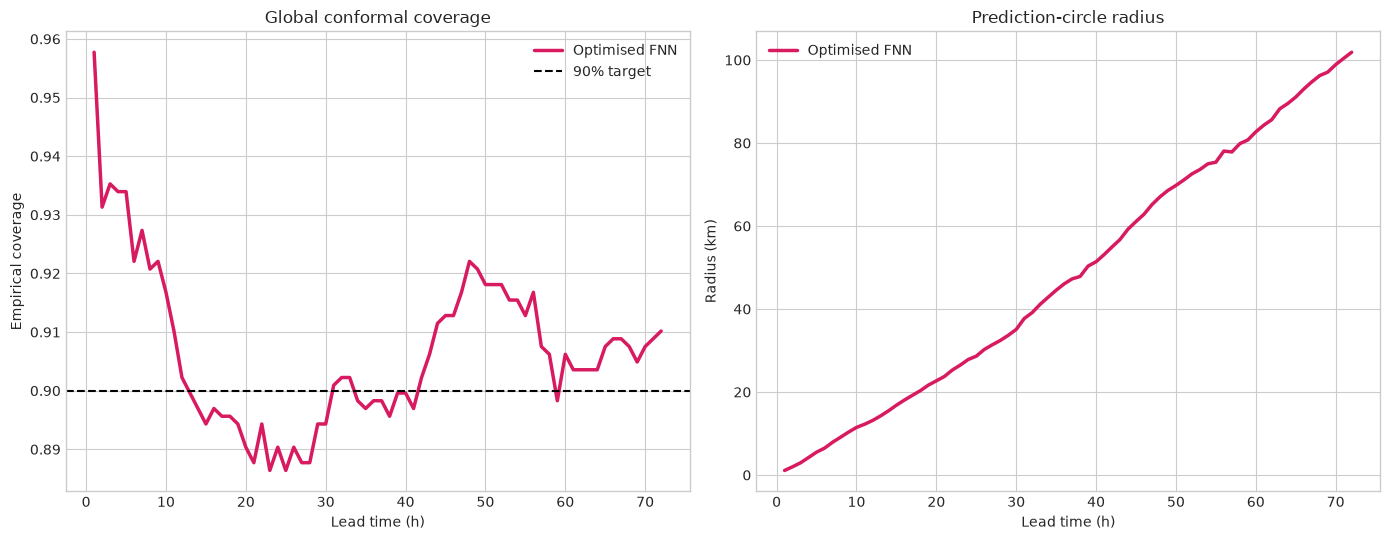

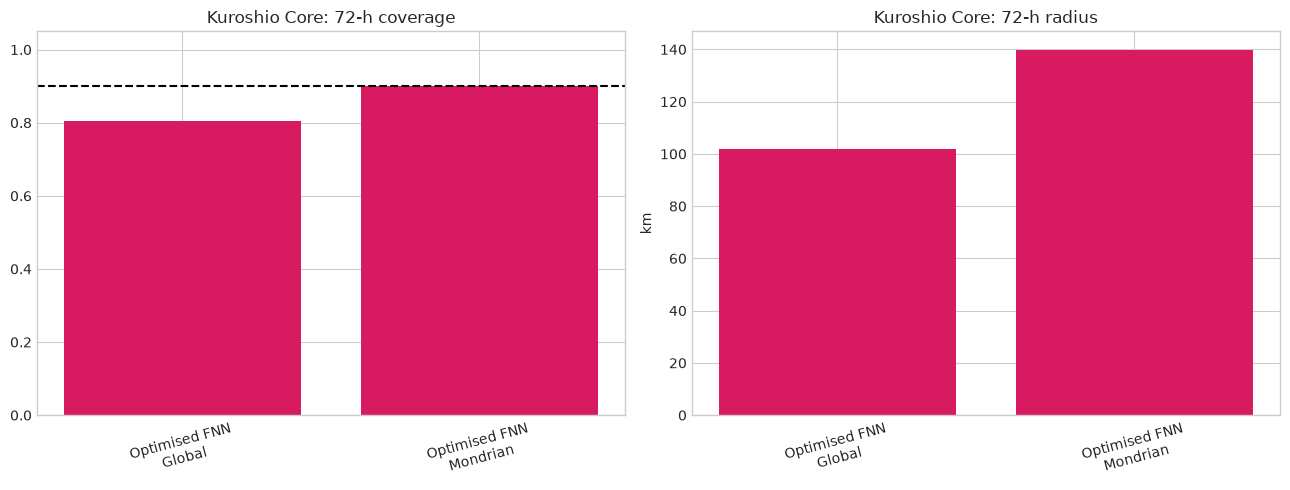

In [ ]:
COLORS={'Optimised FNN':'#d81b60'}
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for model in ERRORS:
    e=ERRORS[model]
    qs=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)])
    d=pd.DataFrame({'lead_time_hours':np.arange(1,73),'coverage':(e['test']<=qs[None,:]).mean(axis=0),'radius_km':qs})
    axes[0].plot(d.lead_time_hours,d.coverage,label=model,color=COLORS[model],lw=2.5)
    axes[1].plot(d.lead_time_hours,d.radius_km,label=model,color=COLORS[model],lw=2.5)
axes[0].axhline(TARGET_COVERAGE,color='black',ls='--',label='90% target')
axes[0].set(xlabel='Lead time (h)',ylabel='Empirical coverage',title='Global conformal coverage')
axes[1].set(xlabel='Lead time (h)',ylabel='Radius (km)',title='Prediction-circle radius')
axes[0].legend(); axes[1].legend(); fig.tight_layout()
fig.savefig(OUT/'optimised_fnn_global_coverage_and_radius.png',dpi=200,bbox_inches='tight'); plt.show()

k=result[result.regime.eq('Kuroshio Core')].copy()
labels=k.model+'\n'+k.method
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].bar(labels,k.coverage_72h,color=[COLORS[x] for x in k.model]); axes[0].axhline(.9,color='black',ls='--'); axes[0].set_ylim(0,1.05); axes[0].set_title('Kuroshio Core: 72-h coverage')
axes[1].bar(labels,k.radius_72h_km,color=[COLORS[x] for x in k.model]); axes[1].set_title('Kuroshio Core: 72-h radius'); axes[1].set_ylabel('km')
for ax in axes: ax.tick_params(axis='x',rotation=15)
fig.tight_layout(); fig.savefig(OUT/'optimised_fnn_kuroshio_conformal.png',dpi=200,bbox_inches='tight'); plt.show()

## 7. Nominal coverage levels: 80%, 90%, and 95%


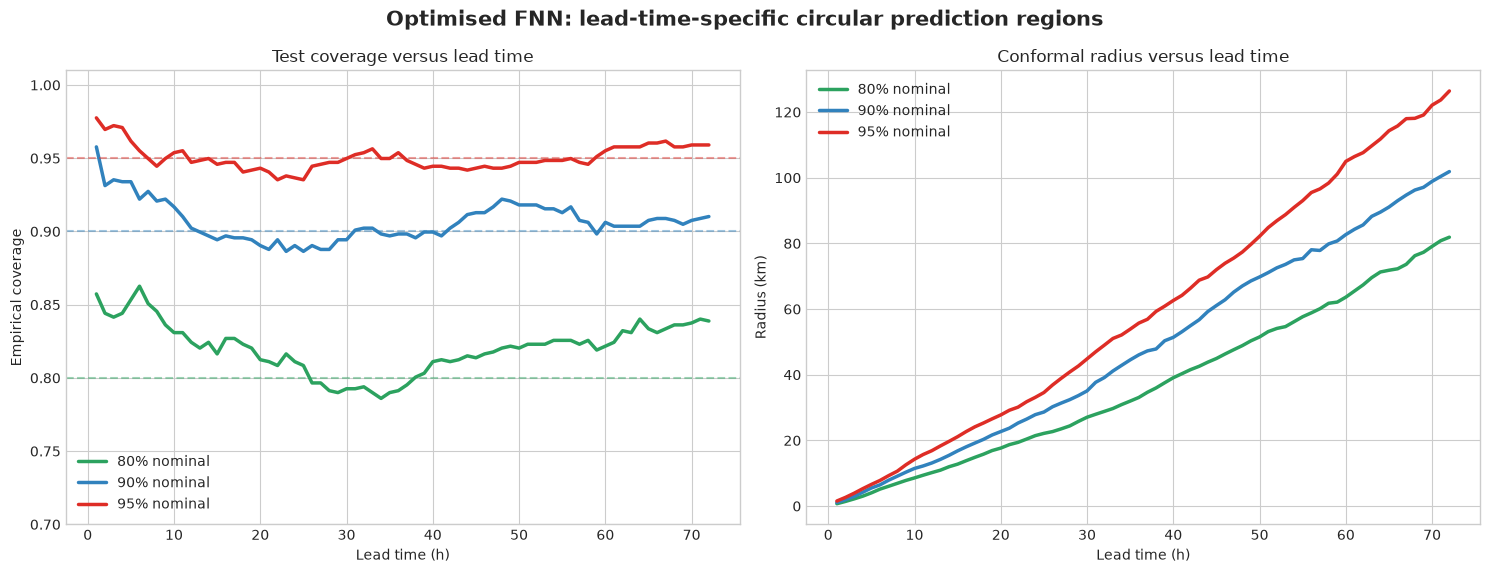

,model,nominal_coverage,empirical_coverage,radius_km
71,Optimised FNN,0.80,0.839,81.887
143,Optimised FNN,0.90,0.910,101.874
215,Optimised FNN,0.95,0.959,126.418


In [ ]:
NOMINAL_LEVELS=[.80,.90,.95]
LEVEL_COLORS={.80:'#2ca25f',.90:'#3182bd',.95:'#de2d26'}
multi_rows=[]

for model,e in ERRORS.items():
    for nominal in NOMINAL_LEVELS:
        q=np.array([conformal_q(e['cal'][:,h],nominal) for h in range(72)])
        coverage=np.mean(e['test']<=q[None,:],axis=0)
        for h in range(72):
            multi_rows.append({'model':model,'nominal_coverage':nominal,
                               'lead_time_hours':h+1,'empirical_coverage':coverage[h],
                               'radius_km':q[h]})

multi_nominal=pd.DataFrame(multi_rows)
multi_nominal.to_csv(OUT/'optimised_fnn_multi_nominal_by_lead.csv',index=False)

for model in ERRORS:
    fig,axes=plt.subplots(1,2,figsize=(15,5.8))
    panel=multi_nominal[multi_nominal.model.eq(model)]
    for nominal in NOMINAL_LEVELS:
        d=panel[panel.nominal_coverage.eq(nominal)].sort_values('lead_time_hours')
        label=f'{int(nominal*100)}% nominal'
        color=LEVEL_COLORS[nominal]
        axes[0].plot(d.lead_time_hours,d.empirical_coverage,color=color,lw=2.5,label=label)
        axes[0].axhline(nominal,color=color,ls='--',alpha=.45)
        axes[1].plot(d.lead_time_hours,d.radius_km,color=color,lw=2.5,label=label)
    axes[0].set(xlabel='Lead time (h)',ylabel='Empirical coverage',
                title='Test coverage versus lead time')
    axes[0].set_ylim(.70,1.01); axes[0].legend(loc='lower left')
    axes[1].set(xlabel='Lead time (h)',ylabel='Radius (km)',
                title='Conformal radius versus lead time')
    axes[1].legend(loc='upper left')
    fig.suptitle(f'{model}: lead-time-specific circular prediction regions',
                 fontsize=15,fontweight='bold')
    fig.tight_layout()
    filename=model.lower().replace(' ','_')+'_multi_nominal_regions.png'
    fig.savefig(OUT/filename,dpi=200,bbox_inches='tight')
    plt.show()

display(multi_nominal[multi_nominal.lead_time_hours.eq(72)]
        [['model','nominal_coverage','empirical_coverage','radius_km']].round(3))

## 8. Summary, limitations, and prediction-region area


In [ ]:
overall=[]
for model,e in ERRORS.items():
    q=np.array([conformal_q(e['cal'][:,h],TARGET_COVERAGE) for h in range(72)])
    overall.append({'model':model,'coverage_72h':np.mean(e['test'][:,-1]<=q[-1]),
                    'radius_72h_km':q[-1],'mean_pointwise_coverage':np.mean(e['test']<=q[None,:]),
                    'mean_radius_km':q.mean()})
overall=pd.DataFrame(overall); overall.to_csv(OUT/'optimised_fnn_conformal_overall.csv',index=False)
display(overall.round(3))
core=result[result.regime.eq('Kuroshio Core')].set_index('method')
display(Markdown(f"""
### Key results (72 h)

- Optimised FNN: overall test coverage **{overall.iloc[0].coverage_72h:.1%}**, global radius **{overall.iloc[0].radius_72h_km:.2f} km** at the 90% nominal level.
- Kuroshio Core: global coverage **{core.loc['Global','coverage_72h']:.1%}**; Mondrian coverage **{core.loc['Mondrian','coverage_72h']:.1%}**.
- Compare coverage and area jointly: a larger radius can improve coverage at a spatial cost.

### Interpretation and limitations

- Cases from the same drifter are correlated. Cluster bootstrap measures sampling uncertainty, not a universal future-coverage guarantee.
- The point forecasting model is fixed; conformal prediction changes the uncertainty region, not point-prediction RMSE.
- Regime assignment must rely only on information available at prediction time; this must be independently verified.
"""))

# Prediction-region area: spherical cap approximation.
def spherical_cap_area_km2(radius_km):
    return 2*np.pi*EARTH_RADIUS_KM**2*(1-np.cos(np.asarray(radius_km)/EARTH_RADIUS_KM))
result['area_72h_km2']=spherical_cap_area_km2(result['radius_72h_km'])
result.to_csv(OUT/'optimised_fnn_conformal_regime_summary.csv',index=False)
area_table=result[['model','method','regime','coverage_72h','radius_72h_km','area_72h_km2']]
area_table.to_csv(OUT/'optimised_fnn_coverage_area_by_regime.csv',index=False)
display(area_table.round(2))

,model,coverage_72h,radius_72h_km,mean_pointwise_coverage,mean_radius_km
0,Optimised FNN,0.91,101.874,0.907,48.391



### Key results (72 h)

- Optimised FNN: overall test coverage **91.0%**, global radius **101.87 km** at the 90% nominal level.
- Kuroshio Core: global coverage **80.6%**; Mondrian coverage **89.9%**.
- Compare coverage and area jointly: a larger radius can improve coverage at a spatial cost.

### Interpretation and limitations

- Cases from the same drifter are correlated. Cluster bootstrap measures sampling uncertainty, not a universal future-coverage guarantee.
- The point forecasting model is fixed; conformal prediction changes the uncertainty region, not point-prediction RMSE.
- Regime assignment must rely only on information available at prediction time; this must be independently verified.


,model,method,regime,coverage_72h,radius_72h_km,area_72h_km2
0,Optimised FNN,Global,Shelf,0.97,101.87,32603.62
1,Optimised FNN,Global,Kuroshio Core,0.81,101.87,32603.62
2,Optimised FNN,Global,Transition,0.88,101.87,32603.62
3,Optimised FNN,Global,Other Offshore,0.95,101.87,32603.62
4,Optimised FNN,Mondrian,Shelf,0.90,61.02,11697.68
5,Optimised FNN,Mondrian,Kuroshio Core,0.90,139.92,61504.17
6,Optimised FNN,Mondrian,Transition,0.92,119.75,45052.24
7,Optimised FNN,Mondrian,Other Offshore,0.93,94.11,27824.84
